# Predicting Major Arrival Delays for U.S. Domestic Flights
## ADS 505 Final Team Project, Team 10 Technical Notebook

- **Team:** Allen Ros, Christopher Guillen, Cameron Moran
- **Course:** ADS 505 Applied Data Science for Business, University of San Diego
- **GitHub repository:** https://github.com/aros-usd/ads-505-final-project

In [1]:
# import statements
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlba
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

# random seed constant
RANDOM_STATE = 123

# file location
DATA_FILE = 'Data/flights_sample_2025H1.csv'

no display found. Using non-interactive Agg backend


# Section 1: Problem Statement and Data Description

**Problem:** About one in five U.S. domestic flights arrives late by 15 minutes or more. A delay costs the airline crew time, fuel, and other resources. This can cause further downstream effects like missed connections and later legs flown by the same aircraft. It can also increase overall terminal traffic and passenger dissatisfaction.

**Data Description:** The dataset was taken from the Bureau of Transportation Statistics (BTS). It has one row per non-stop domestic flight leg and 109 fields. We downloaded January through June of 2025 (~3.5 million flights) and sampled 5,000 flights from each month to create a manageable dataset for modeling. We also only selected a subset of 17 columns from the original 109 to reduce the dimensionality of the dataset and to avoid data leakage.

- The dataset was built by downloading the BTS monthly files for January through June of 2025 and using the `build_sample.py` script to create a random sample of 5,000 flights from each month, creating a 30,000-row dataset.
- Diverted and Cancelled flights were removed, as they have no arrival delay to predict
- 16 of the 17 columns are features and 1 is the target (ArrDel15).

**Objective:** Build and compare classification models that predict whether a scheduled domestic flight will arrive 15 or more minutes late (`ArrDel15 = 1`). The model should also identify which schedule characteristics are most associated with delay.

In [2]:
# load the dataset and view a few rows
flights_df = pd.read_csv(DATA_FILE)
print(f'Dataset shape: {flights_df.shape}')
flights_df.head()

Dataset shape: (30000, 17)


,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Origin,OriginState,Dest,DestState,CRSDepTime,DepTimeBlk,CRSArrTime,ArrDel15,ArrTimeBlk,CRSElapsedTime,Distance,DistanceGroup
0,1,1,3,2025-01-01,B6,JFK,NY,FLL,FL,501,0001-0559,804,0.0,0800-0859,183.0,1069.0,5
1,1,1,3,2025-01-01,AA,ORD,IL,CLT,NC,502,0001-0559,808,0.0,0800-0859,126.0,599.0,3
2,1,1,3,2025-01-01,OH,GRR,MI,DCA,VA,547,0001-0559,738,0.0,0700-0759,111.0,524.0,3
3,1,1,3,2025-01-01,WN,PDX,OR,DEN,CO,550,0001-0559,920,0.0,0900-0959,150.0,991.0,4
4,1,1,3,2025-01-01,AA,MSP,MN,MIA,FL,550,0001-0559,1103,0.0,1100-1159,253.0,1501.0,7


# Section 2: Exploratory Data Analysis

In [3]:
# start by separating the features and target variables
feature_cols = [
    "Month",
    "DayofMonth",
    "DayOfWeek",
    "FlightDate",
    "Reporting_Airline",
    "Origin",
    "Dest",
    "OriginState",
    "DestState",
    "CRSDepTime",
    "DepTimeBlk",
    "CRSArrTime",
    "ArrTimeBlk",
    "CRSElapsedTime",
    "Distance",
    "DistanceGroup",
]
target_col = [ 
    "ArrDel15"
]

*The 16 feature columns describe when a flight is scheduled (date, day, times), who operates it (airline), and where it flies (airports, states, distance). All of them are known before departure. ArrDel15 is the classification target.*

In [4]:
# check overall delay rate of dataset
delay_rate = flights_df['ArrDel15'].mean()
print(f'Overall delay rate: {delay_rate:.4f} ({delay_rate*100:.2f}%)')

Overall delay rate: 0.2191 (21.91%)


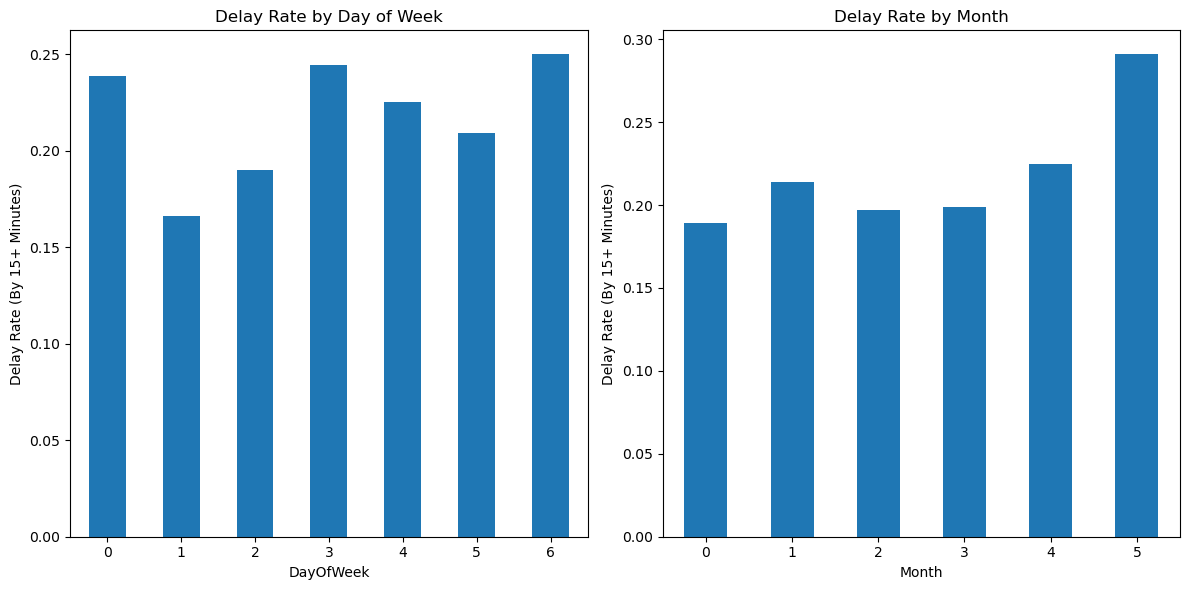

In [5]:
# delay rate by day of week and by month
delay_rate = flights_df['ArrDel15'].mean()
by_day = flights_df.groupby('DayOfWeek')['ArrDel15'].mean()
by_month = flights_df.groupby('Month')['ArrDel15'].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, dataset in enumerate([by_day, by_month]):
    dataset.plot(kind='bar', ax=axes[i])
    axes[i].set_ylabel('Delay Rate (By 15+ Minutes)')
    axes[i].set_title(f'Delay Rate by {"Day of Week" if i == 0 else "Month"}')
    axes[i].set_xticklabels(axes[i].get_xticks(), rotation=0)


plt.tight_layout()
plt.show()

*The overall delay rate is ~21.9%. Tuesday (DayOfWeek = 1) is the best day in terms of lowest delay rates (~17%) and Sunday is the worst (~25%). This means there is a very present spread in delay rates across days. There is also a spread across months, with January having the lowest (~18%) and June having the highest (~29%).*

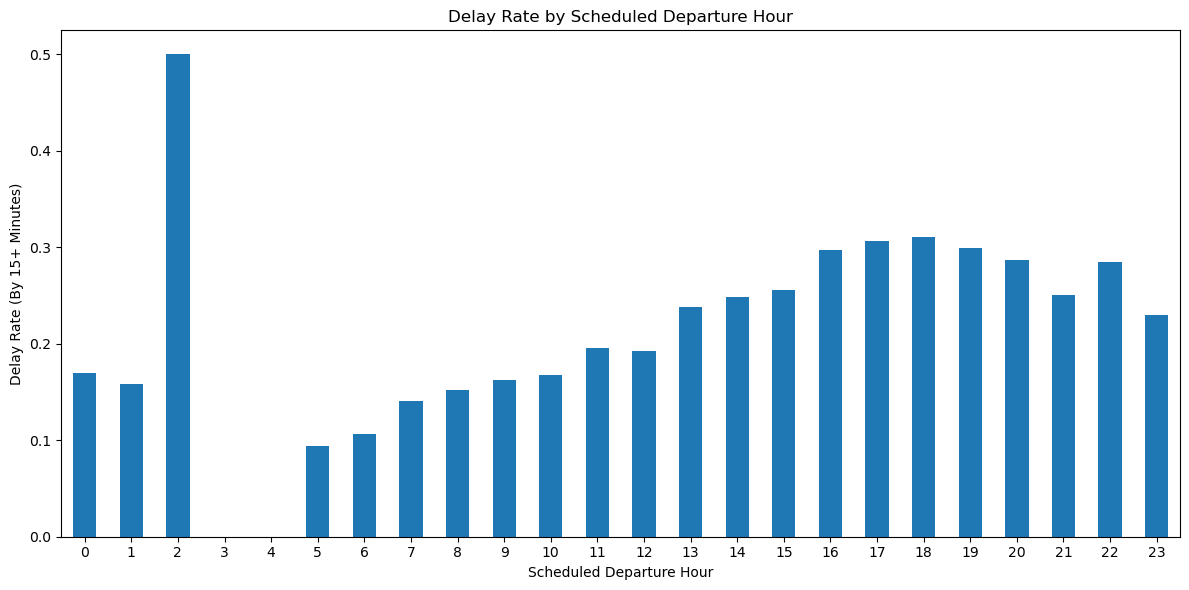

Flights per hour:
CRSDepTime
0       47
1       19
2        2
3        2
4        3
5      882
6     1993
7     2151
8     2077
9     1628
10    1786
11    1978
12    1727
13    1826
14    1788
15    1723
16    1835
17    1918
18    1829
19    1586
20    1354
21     977
22     647
23     222
Name: size, dtype: int64


In [6]:
# delay rate by scheduled departure time (CRSDepTime)
hours_df = flights_df.copy()
hours_df['CRSDepTime'] = hours_df['CRSDepTime'] // 100
hour_stats = hours_df.groupby('CRSDepTime')['ArrDel15'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(12, 6))
hour_stats['mean'].plot(kind='bar', ax=ax)
ax.set_xlabel('Scheduled Departure Hour')
ax.set_ylabel('Delay Rate (By 15+ Minutes)')
ax.set_title('Delay Rate by Scheduled Departure Hour')
ax.set_xticklabels(ax.get_xticks(), rotation=0)

plt.tight_layout()
plt.show()

# print flights per hour as support for the figure
print("Flights per hour:")
print(hour_stats['size'])

*Flights between 0 and 4 AM are very uncommon so their rates may be heavily skewed if any flights are delayed for those times in the sample. Ignoring these and looking strictly at the data from 5 AM onwards, we see a clear pattern. Flights leaving at 5-6 a.m. are delayed about 10% of the time, and the rate climbs steadily through the day to about 30% for 4-8 PM flights. This makes sense as delays early in the day can compound and propagate out to the flights that follow.*

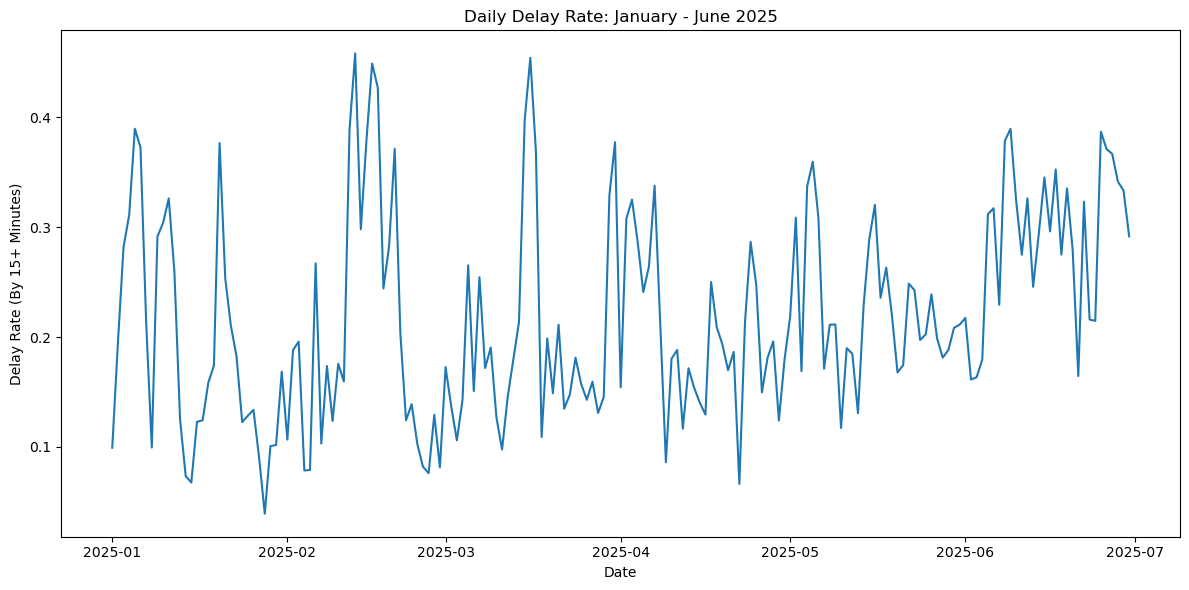

In [7]:
# delay rate by day
daily_rate = flights_df.groupby('FlightDate')['ArrDel15'].mean()
daily_rate.index = pd.to_datetime(daily_rate.index)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(daily_rate.index, daily_rate.values)
ax.set_title('Daily Delay Rate: January - June 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Delay Rate (By 15+ Minutes)')

plt.tight_layout()
plt.show()

*The daily delay rate is very volatile. It ranges from  ~3-5% to ~45-47%. Fluctuations are likely caused by a variety of factors. Weather delays, aircraft issues, etc. can cause these delays. The goal is to understand underlying patterns and factors that contribute to these delays.*

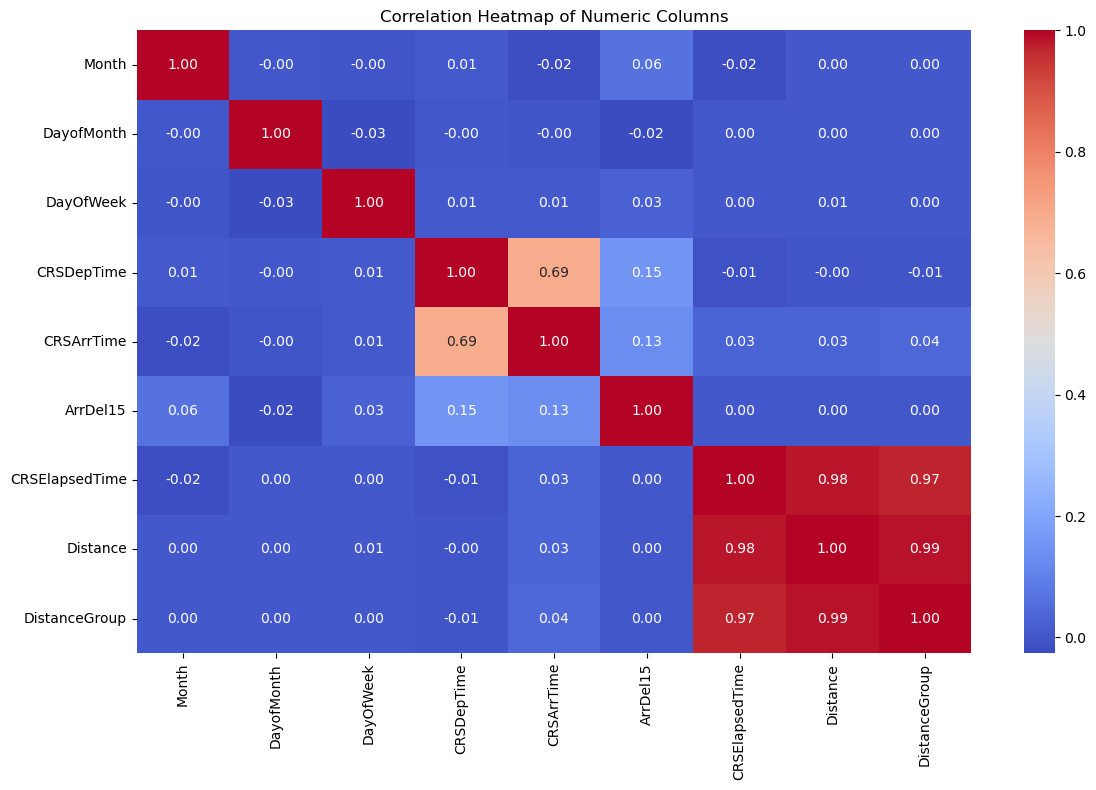

In [8]:
# correlation heatmap of the numeric features and targets
correlations = flights_df.select_dtypes(include='number').corr()

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Correlation Heatmap of Numeric Columns')

plt.tight_layout()
plt.show()


- *CRSElapsedTime, Distance, and DistanceGroup are almost perfectly correlated (about 0.97-0.99), because elapsed time is a function of distance. Keeping all three would result in multicollinearity, so Section 3 will handle this by dropping 1 or more of these columns.*

- *CRSDepTime and CRSArrTime are strongly correlated (about 0.68). A flight that departs later usually arrives later, but the correlation is not strong enough to warrant removing one or the other.*

- *The two target columns are strongly correlated with each other, which is to be expected. Every feature has only a weak  correlation with ArrDel15. This does not mean the features will be useless in predictions. The bar charts above show patterns (hour of day, month) that individual features alone cannot capture.*

# Section 3: Data Pre-Processing

In [9]:
# first step is to check for missing values in the dataset
flights_df.isnull().sum()

Month                0
DayofMonth           0
DayOfWeek            0
FlightDate           0
Reporting_Airline    0
Origin               0
OriginState          0
Dest                 0
DestState            0
CRSDepTime           0
DepTimeBlk           0
CRSArrTime           0
ArrDel15             0
ArrTimeBlk           0
CRSElapsedTime       0
Distance             0
DistanceGroup        0
dtype: int64

*No missing values, so no need for imputation or dropping rows.*

In [10]:
# drop DistanceGroup due to high correlation with Distance
# keep CRSElapsedTime until after the outlier analysis
flights_df.drop(columns=['DistanceGroup'], inplace=True)


*Distance, DistanceGroup, and CRSElapsedTime are highly correlated, so we will keep only one of them. DistanceGroup and CRSElapsedTime are derived from Distance, so we will keep Distance and drop the other two.*

In [11]:
# feature engineering to create columns for weekend and holiday booleans
flights_df['FlightDate'] = pd.to_datetime(flights_df['FlightDate'])

# weekend flag (BTS codes DayOfWeek as Monday = 1 ... Sunday = 7)
flights_df['is_weekend'] = (flights_df['DayOfWeek'] >= 6).astype(int)

# add a holiday flag for flights within 3 days of a major US holiday
holidays = pd.to_datetime([
    '2025-01-01',  # New Year's Day
    '2025-01-20',  # Martin Luther King Jr. Day
    '2025-02-17',  # Presidents' Day
    '2025-04-20',  # Easter
    '2025-05-26',  # Memorial Day
    '2025-06-19',  # Juneteenth
])

def days_to_nearest_holiday(flight_date):
    return min(abs((flight_date - holiday).days) for holiday in holidays)

days_to_holiday = flights_df['FlightDate'].apply(days_to_nearest_holiday)
flights_df['is_holiday'] = (days_to_holiday <= 3).astype(int)

In [12]:
# convert departure and arrival times to hours for binning
# CRSDepTime and CRSArrTime are integers like 1836 so dividing by 100 gives the hour
flights_df['departure_hour'] = flights_df['CRSDepTime'] // 100
flights_df['arrival_hour'] = flights_df['CRSArrTime'] // 100

# drop the original time columns since they are no longer needed
flights_df.drop(columns=['CRSDepTime', 'CRSArrTime', 'DepTimeBlk', 'ArrTimeBlk'], inplace=True)

In [13]:
# check for outliers by Distance and CRSElapsedTime using IQR method
for col in ['Distance', 'CRSElapsedTime']:
    q1 = flights_df[col].quantile(0.25)
    q3 = flights_df[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((flights_df[col] < q1 - 1.5 * iqr) | (flights_df[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: {n_out} outliers ({n_out / len(flights_df):.1%})')

# print 10 outliers for each column
for col in ['Distance', 'CRSElapsedTime']:
    q1 = flights_df[col].quantile(0.25)
    q3 = flights_df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = flights_df[(flights_df[col] < q1 - 1.5 * iqr) | (flights_df[col] > q3 + 1.5 * iqr)]
    print(f'\n{col} outliers:')
    print(outliers[['OriginState', 'DestState', col, 'ArrDel15']].head(10))
    

Distance: 1714 outliers (5.7%)
CRSElapsedTime: 1554 outliers (5.2%)

Distance outliers:
    OriginState DestState  Distance  ArrDel15
12           CA        NY    2475.0       0.0
19           CA        NC    2296.0       0.0
38           CA        HI    2367.0       0.0
57           NJ        NV    2227.0       0.0
65           NY        CA    2475.0       0.0
71           CA        HI    2615.0       0.0
97           NV        HI    2762.0       0.0
148          CA        MA    2704.0       0.0
158          WA        FL    2717.0       1.0
160          CA        VA    2253.0       1.0

CRSElapsedTime outliers:
   OriginState DestState  CRSElapsedTime  ArrDel15
12          CA        NY           324.0       0.0
26          FL        AZ           311.0       0.0
28          PR        IL           319.0       0.0
38          CA        HI           345.0       0.0
46          VA        AZ           328.0       0.0
57          NJ        NV           340.0       0.0
62          MI        C

*The outliers in Distance and CRSElapsedTime do not seem to be errors, they just seem to be longer flights (Ex: CA to NY or CA to HI). These will not be removed because they are valid flights and any model should be able to handle them.*

In [14]:
# drop CRSElapsedTime after completing the outlier analysis
flights_df.drop(columns=['CRSElapsedTime'], inplace=True)

# state columns are also not necessary because the airport columns already capture the information
# they were just retained to this point for the above outlier analysis, but they can be dropped now
flights_df.drop(columns=['OriginState', 'DestState'], inplace=True)

# also drop FlightDate and DayofMonth because models should not be able to use them to generalize to future flights
flights_df.drop(columns=['FlightDate', 'DayofMonth'], inplace=True)

In [15]:
# finalize feature cols and make a new model_df copy
feature_cols = [
    "Month",
    "DayOfWeek",
    "Reporting_Airline",
    "Origin",
    "Dest",
    "Distance",
    # engineered features
    "is_weekend",
    "is_holiday",
    "departure_hour",
    "arrival_hour",
]
model_df = flights_df[feature_cols + target_col].copy()
print(f'Model dataset shape: {model_df.shape}')

Model dataset shape: (30000, 11)


In [16]:
# use one-hot encoding for categorical features and standard scaling for numeric features
categorical_features = [
    'Month',
    'DayOfWeek',
    'Reporting_Airline',
    'Origin',
    'Dest'
]
numeric_features = [
    'Distance',
    'departure_hour',
    'arrival_hour'
]
binary_features = [
    'is_weekend',
    'is_holiday'
]
oce = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
scaler = StandardScaler()

# combine the steps into one preprocessor, binary features pass through unchanged
# it is only defined here and will be used in section 4
preprocessor = ColumnTransformer([
    ('categorical', oce, categorical_features),
    ('numeric', scaler, numeric_features),
    ('binary', 'passthrough', binary_features),
])

# Section 4: Data Splitting

In [17]:
# separate predictors and target (target_col is a list, so take the single column as a Series)
x = model_df[feature_cols]
y = model_df[target_col[0]]

# stratified 60/20/20 split (train, test, validation)
# you can't split in one step, so split twice (once into 60/40, then split the 40 into 20/20)
x_train, x_temp, y_train, y_temp = train_test_split(x, y, train_size=0.6, stratify=y, random_state=RANDOM_STATE)
x_valid, x_test, y_valid, y_test = train_test_split(x_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

# confirm the sizes and that the delay rate is the same in every set
for name, target in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]:
    print(f'{name} rows = {len(target)}, Delay Rate = {target.mean():.1%}')

Train rows = 18000, Delay Rate = 21.9%
Validation rows = 6000, Delay Rate = 21.9%
Test rows = 6000, Delay Rate = 21.9%


In [18]:
# fit learns the data and transform applied the learned transformation to the data
# we only want to fit on the training data, then apply the same transformation to the validation and test data
# this is because learning the scaling or one-hot encoding from the validation or test data would be a form of data leakage 
x_train_prepared = preprocessor.fit_transform(x_train)
x_valid_prepared = preprocessor.transform(x_valid)
x_test_prepared = preprocessor.transform(x_test)
print(f'Encoded Shapes:')
print(f'Train {x_train_prepared.shape}')
print(f'Validation {x_valid_prepared.shape}')
print(f'Test {x_test_prepared.shape}')

Encoded Shapes:
Train (18000, 658)
Validation (6000, 658)
Test (6000, 658)


# Section 5: Model Building Strategy

In [19]:
# baseline plus my three models; class_weight='balanced' because only ~1 in 5 flights is late
models = {
    'Baseline (always on-time)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
}

# fit on train, score on validation (test set stays untouched until the end)
rows = []
for name, model in models.items():
    model.fit(x_train_prepared, y_train)
    pred = model.predict(x_valid_prepared)
    proba = model.predict_proba(x_valid_prepared)[:, 1]
    rows.append({
        'model': name,
        'precision': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred),
        'roc_auc': roc_auc_score(y_valid, proba),
    })
baseline_results = pd.DataFrame(rows).sort_values('roc_auc', ascending=False)
baseline_results

,model,precision,recall,roc_auc
3,Hist Gradient Boosting,0.310983,0.574905,0.654491
2,Random Forest,0.459770,0.060837,0.648827
1,Logistic Regression,0.294210,0.571863,0.621428
0,Baseline (always on-time),0.000000,0.000000,0.500000


*We built three classifiers (logistic regression, random forest, and histogram gradient boosting) plus a dummy baseline that always predicts on-time, so we can show the models actually beat guessing. The baseline gets a ROC AUC of 0.50 and catches no late flights. Only about 22% of flights are late, so each model uses balanced class weights so it does not just ignore the delayed flights. All three were fit on the training set and scored on the validation set, and the test set stays untouched until the final evaluation. With default settings, gradient boosting and random forest tied on ROC AUC (about 0.65) and logistic regression trailed at 0.62. Random forest had the best precision (0.39) but caught far fewer late flights (recall 0.28), while boosting and logistic regression caught over half (recall about 0.57).*

# Section 6: Model Performance and Hyperparameter Tuning

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10]},  # small grid, sklearn will just warn and try all 4
    'Random Forest': {
        'n_estimators': [200, 400],
        'max_depth': [10, 20, None],
        'min_samples_leaf': [1, 5, 20],
        'max_features': ['sqrt', 0.3],
    },
    'Hist Gradient Boosting': {
        'learning_rate': [0.03, 0.05, 0.1],
        'max_depth': [3, 5, None],
        'max_iter': [100, 200, 400],
        'min_samples_leaf': [20, 50, 100],
        'l2_regularization': [0, 1, 10],
    },
}

tuned_models, rows = {}, []
for name, grid in param_grids.items():
    search = RandomizedSearchCV(models[name], grid, n_iter=10, scoring='roc_auc',
                                cv=cv, n_jobs=-1, random_state=RANDOM_STATE)
    search.fit(x_train_prepared, y_train)
    best = search.best_estimator_
    tuned_models[name] = best
    pred = best.predict(x_valid_prepared)
    rows.append({
        'model': name,
        'best_params': search.best_params_,
        'cv_roc_auc': search.best_score_,
        'valid_precision': precision_score(y_valid, pred),
        'valid_recall': recall_score(y_valid, pred),
        'valid_roc_auc': roc_auc_score(y_valid, best.predict_proba(x_valid_prepared)[:, 1]),
    })
tuned_results = pd.DataFrame(rows).sort_values('valid_roc_auc', ascending=False)
tuned_results

,model,best_params,cv_roc_auc,valid_precision,valid_recall,valid_roc_auc
2,Hist Gradient Boosting,"{'min_samples_leaf': 100, 'max_iter': 400, 'ma...",0.661005,0.305896,0.587833,0.656428
1,Random Forest,"{'n_estimators': 400, 'min_samples_leaf': 1, '...",0.657835,0.327852,0.485171,0.652701
0,Logistic Regression,{'C': 0.01},0.645614,0.297257,0.601521,0.638219


*We tuned each model with a randomized search using 5-fold stratified cross-validation on the training data, scored on ROC AUC. ROC AUC was used for tuning because recall alone can be inflated by predicting every flight as late. Tuning helped a little: validation ROC AUC went from 0.651 to 0.655 for gradient boosting, 0.649 to 0.654 for random forest, and 0.621 to 0.638 for logistic regression. Gradient boosting and random forest are essentially tied (0.655 vs 0.654), and they also tied in cross-validation (about 0.66). Gradient boosting caught about 59% of late flights with 31% precision, compared to 56% and 32% for random forest. The overall performance is modest, which makes sense because the features only describe the schedule and do not include weather or aircraft information. Final model selection is in Section 7.*

# Section 7: Results and Final Model Selection

The tuned Histogram Gradient Boosting model was selected based on *validation ROC AUC*, which measures how well a model ranks delayed flights above on-time flights across classification thresholds. Its validation ROC AUC was *0.6546*, slightly above Random Forest (*0.6537*) and Logistic Regression (*0.6382*). The difference from Random Forest is very small, so we should not interpret this as strong evidence that boosting is consistently better.

At the default classification threshold, Histogram Gradient Boosting identified approximately *59.3%* of delayed flights, with *30.9% precision*. This tradeoff matters operationally: a delay alert catches some genuine delays but also generates false alarms. We chose ROC AUC for model comparison rather than accuracy, because approximately 78% of flights are on time. The untouched test set is evaluated *once* below to estimate how well the selected model generalizes.

In [21]:
# Final evaluation: use the test set only after model selection.
final_model = tuned_models['Hist Gradient Boosting']
test_predictions = final_model.predict(x_test_prepared)
test_probabilities = final_model.predict_proba(x_test_prepared)[:, 1]

final_results = pd.DataFrame([{
    'Model': 'Hist Gradient Boosting',
    'Test precision': precision_score(y_test, test_predictions, zero_division=0),
    'Test recall': recall_score(y_test, test_predictions, zero_division=0),
    'Test ROC AUC': roc_auc_score(y_test, test_probabilities),
}])
final_results.round(3)

,Model,Test precision,Test recall,Test ROC AUC
0,Hist Gradient Boosting,0.306,0.61,0.653


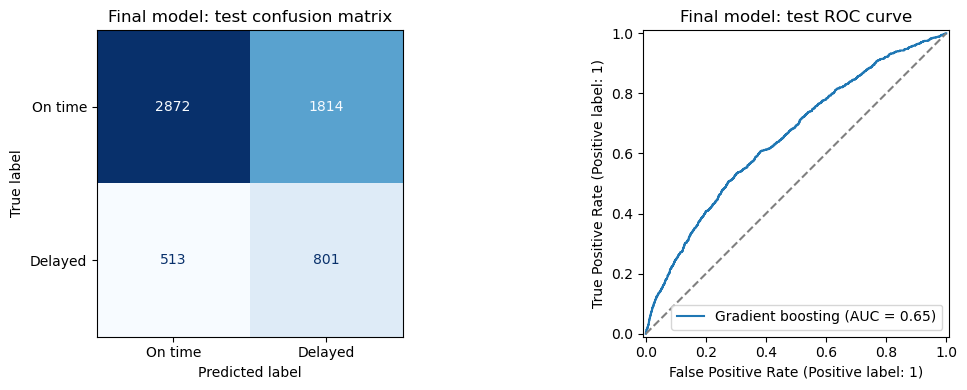

In [22]:
# Review the types of correct and incorrect predictions.
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=['On time', 'Delayed'],
    cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Final model: test confusion matrix')

RocCurveDisplay.from_predictions(
    y_test, test_probabilities, ax=axes[1], name='Gradient boosting'
)
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('Final model: test ROC curve')
plt.tight_layout()
plt.show()

The test table and figures above provide the final performance estimate. The confusion matrix shows how many delayed flights were detected versus missed, as well as how many on-time flights were incorrectly flagged. The ROC curve summarizes the ranking tradeoff over different thresholds. *Do not tune the model again using test results*; any further threshold or model changes should be developed on the validation set and assessed on new holdout data.

*Operational interpretation:* This model is more appropriate as an early warning or prioritization tool than as an automated decision-maker. Airlines would need to determine whether catching more delays justifies the workload caused by false alerts. The optimal alert threshold depends on those costs and cannot be determined from ROC AUC alone.

# Section 8: Discussion and Conclusion

Our analysis suggests that flight schedules contain some useful information for predicting major arrival delays, but they do not explain the full problem. The overall delay rate in the sample is about *21.9%*, and the EDA showed meaningful differences by scheduled departure hour, day of week, and date. The tuned models improved on the always-on-time baseline (ROC AUC *0.50*), but the best validation ROC AUC of approximately *0.655* indicates only moderate predictive discrimination.

*Limitations.* The dataset is a 30,000-flight sample from the first half of 2025, so results may change for other periods, airports, or operating conditions. The models use schedule-related information available before departure but do not include weather, air traffic restrictions, incoming aircraft delays, or maintenance issues. Those omitted factors can have a major influence on arrival delays. In addition, the random stratified split does not simulate forecasting on later dates; a chronological holdout would be a stronger test of real-world deployment. The one-hot encoding of airports also creates many features, and rare routes may have limited training examples.

*Recommended next steps.* Add operational and weather data that would actually be available at prediction time, evaluate a time-based holdout, check results by airline, airport, and season, and assess probability calibration. Work with operations stakeholders to assign costs to missed delays and false alarms, then choose an alert threshold using validation data. Monitor model performance and changing delay rates after deployment.

## Model Brief — Technical Handoff

*Objective and approach.* We modeled `ArrDel15` as a binary outcome using flight schedule, carrier, airport, distance, and engineered calendar/time features. After cleaning the data and preparing the predictors, we split it into training, validation, and test sets. Preprocessing was fitted on the training data to avoid leakage. We created stratified training (60%), validation (20%), and test (20%) partitions and fit preprocessing on the training data only.

*Models tested and rationale.* We compared an always-on-time dummy baseline, Logistic Regression, Random Forest, and Histogram Gradient Boosting. Logistic Regression provided a straightforward linear benchmark; Random Forest allowed nonlinear relationships and interactions; and gradient boosting offered a second nonlinear approach. We tuned the three substantive models with stratified five-fold cross-validation using ROC AUC, then compared their validation performance.

*Decision and what we learned.* We selected tuned Histogram Gradient Boosting for final test evaluation because it achieved the highest validation ROC AUC (*0.6546*), narrowly ahead of Random Forest (*0.6537*). Its validation recall (*0.5932*) exceeded Random Forest's (*0.5635*), although its precision was slightly lower (*0.3089* versus *0.3161*). The very small ROC AUC difference means model selection is not definitive; performance and operational costs should be rechecked on new data.

*Known risks and handoff recommendation.* Limited predeparture features constrain accuracy, and the random split may overstate performance under future conditions. Treat predictions as decision support rather than guaranteed delay forecasts. Before production use, perform a chronological evaluation, assess performance across important subgroups, validate probability calibration, and select a decision threshold based on the actual cost of false alerts and missed delays.

*Repository:* https://github.com/aros-usd/ads-505-final-project